# Roc Tutorial

Welcome to Roc, a A fast, friendly, functional language! This notebook is an executable adaptation of the [Roc tutorial](https://github.com/roc-lang/roc/blob/main/docs/mini-tutorial-new-compiler.md).

## Setup Roc on Colab

1. In a fresh Colab runtime, run the cell below to install Roc, then **refresh the page**.
2. Roc is now active. Skip setup and run the Roc cells in order.

Repeat setup only after Colab resets the runtime. In local Jupyter with iRoc installed, select the **Roc** kernel and delete this setup section.


In [ ]:
!curl -fSL https://raw.githubusercontent.com/ageron/iRoc/main/scripts/setup_colab.py -o /content/setup_iroc.py
%run /content/setup_iroc.py

## Let's Roc! 🤘

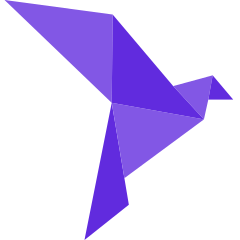

In [ ]:
Svg(
  \\<svg width="240" height="240" viewBox="0 0 51 53" fill="none" xmlns="http://www.w3.org/2000/svg">
  \\  <path d="M23.6751 22.7086L17.655 53L27.4527 45.2132L26.4673 39.3424L23.6751 22.7086Z" fill="#612BDE"/>
  \\  <path d="M37.2438 19.0101L44.0315 26.3689L45 22L45.9665 16.6324L37.2438 19.0101Z" fill="#8257E5"/>
  \\  <path d="M23.8834 3.21052L0 0L23.6751 22.7086L23.8834 3.21052Z" fill="#8257E5"/>
  \\  <path d="M44.0315 26.3689L23.6751 22.7086L26.4673 39.3424L44.0315 26.3689Z" fill="#8257E5"/>
  \\  <path d="M50.5 22L45.9665 16.6324L45 22H50.5Z" fill="#612BDE"/>
  \\  <path d="M23.6751 22.7086L44.0315 26.3689L37.2438 19.0101L23.8834 3.21052L23.6751 22.7086Z" fill="#612BDE"/>
  \\</svg>
)

## Expressions and definitions

Ok, let's start!

An expression produces a value. Run a cell with **Shift+Enter**; its last expression is displayed below it.

In [1]:
1 + 1

2.0

You can define names and use them in later inputs. `=` gives a name to a value; `*` multiplies two values:

In [2]:
two = 1 + 1
two * 2

4.0

### Constants

This line defines a new _constant_ called `name`:

Text in double quotes is a string; `"Rocco"` below is one.

In [3]:
name = "Rocco"
name

"Rocco"

Constants should not be reassigned or shadowed, if you try to do `name =` again in the same scope, 
`roc` will give a compile-time warning with exit code 2. That way, you can quickly write something with
shadowing if you want but the non-zero exit code prevents it from ending up in production code because CI will fail.

The REPL lets you replace top-level definitions while experimenting. Inside the examples, we'll use different names to avoid shadowing a constant. A string is text in double quotes, like `"Rocco"` above.

## Functions

`|value| value * 2` is Roc syntax for an anonymous function with one argument, named `value`. (If it had multiple arguments, it would look like `|arg1, arg2| ...` instead.) Functions in Roc are ordinary values, just like numbers or strings; we can pass them around and use `=` to name them.

Call a function by putting its arguments in parentheses after its name:

In [4]:
double = |value| value * 2
double(5)

10.0

### Blocks

Every Roc function has one expression after its arguments, but that expression can be a *block* if you like. Block expressions go inside curly braces. They end with an expression, and the entire block evaluates to whatever that expression evaluates to. This is why, when we use curly braces in functions, the function returns whatever is at the end of the curly braces—that's just how blocks work!

For example:

In [5]:
double_then_add_one = |value| {
    doubled = value * 2
    doubled + 1
}
double_then_add_one(5)

11.0

### Pure and effectful functions

Printing output or reading a file is a [_side effect_](https://en.wikipedia.org/wiki/Side_effect_(computer_science)): it interacts with the world outside the value a function returns. In Roc, we call functions that can run side effects _effectful functions_, and by convention we always name them with a `!` at the end of their names. In contrast, [_pure functions_](https://en.wikipedia.org/wiki/Pure_function) don't have a `!` at the end of their names. The arithmetic functions above are pure.

### `dbg` statements

You can use the `dbg` keyword for the classic technique of _printline debugging_, like so. A line starting with `#` is a comment; Roc ignores it:

In [6]:
# dbg(5) works too
dbg 5

5.0


{}

Although printing is an I/O operation, the `dbg` statement can be used even in pure functions. Roc checks and translates code before executing it; this preparation is called compilation. `dbg` works in two different ways:

- Roc evaluates top-level constants at compile time. If evaluating one calls a pure function containing `dbg`, you'll see the `dbg` output at compile time. (Evaluating known expressions ahead of time is called [constant folding](https://en.wikipedia.org/wiki/Constant_folding).)
- At runtime, `dbg` may work differently depending on where you're running the program. For example, in a command-line application it may be printed to stderr. However, when running a Roc program that's compiled to WebAssembly and running in the browser, it would likely appear in the browser console instead.

Note that Roc's compile-time evaluation means there is no guarantee that a given `dbg` will run at runtime or at compile time.

In iRoc, captured `dbg` output appears beneath the cell. `dbg` can show us intermediate values, even when they aren't the cell's last expression.

The official tutorial uses `echo!` to print its examples. The REPL doesn't provide it, so let's define a little helper using `dbg`. The braces contain the function body, and `x` is the value to display. This helper is just a notebook convenience, rather than a general-purpose output API; it retains `dbg`'s debugging behavior. A call may also display `{}`, Roc's empty record, which has no fields and carries no information.

In [7]:
echo! = |x| { dbg x }

In [8]:
echo!("Hello, World!")

"Hello, World!"


{}

Hooray!

### Calling methods

A *type* describes what kind of value something is—for example, a number or a string. Roc names the string type `Str`. A *method* is a function associated with a particular type. You call it using a dot after the value: `value.to_str()` calls that value's `to_str` method. The empty parentheses mean there are no extra arguments.

For numbers, `to_str` converts the number into a string. We'll use it to put numbers into messages.

### String interpolation

The string `"Hello, ${name}!"` will evaluate to `"Hello, Rocco!"`.

In an ordinary string interpolation, each interpolated expression must also produce a string; Roc does not automatically convert other types. For example, if you wanted to print a number you'd need to call `to_str` on it like so:

In [9]:
"Hello, ${name}!"

"Hello, Rocco!"

Let's give `thing_count` a value first. Plain number literals are all we need here. Roc displays them as decimal numbers (so `3` appears as `3.0`); we'll introduce integer types later:

In [10]:
thing_count = 3
echo!("Number of things: ${thing_count.to_str()}")

"Number of things: 3.0"


{}

You can put any expression you like inside a string interpolation. If you really wanted to, you could do something like this:

`/` divides, and `.negate()` changes a number's sign. The parentheses group the arithmetic before we convert its result to a string.

In [11]:
numerator = 8
denominator = 2
echo!("Answer: ${((numerator / denominator) + 1).negate().to_str()}")

"Answer: -5.0"


{}

...but at that point it'd probably be easier to read if you extracted that expression into a constant.

### Lists

In Roc, a `List` looks like this:

In [12]:
animals = ["bird", "crab", "lizard"]
animals

["bird", "crab", "lizard"]

Lists keep their elements in order. All items in a list must have compatible types; `[]` is an empty list. We'll use lists of digits shortly.

### Method Calling

You can get the length of the list by calling `List.len(animals)`, or as a shortcut, you can just call `animals.len()`.

Both of them do the same thing. When you call `.len()`, Roc's type inference knows that the type of `animals` is `List`,
so it translates that `animals.len()` call into `List.len(animals)` at compile time. `.len()` is known as a _method_ because
it's a function that is associated with a particular type (in this case, `List`).

In [13]:
List.len(animals)

3

In [14]:
animals.len()

3

### Booleans and comparisons

A Boolean is either `True` or `False`. `==` compares two values for equality; `!` before a Boolean reverses it. Don't confuse this prefix `!` with the `!` at the end of a function name.

The `is_empty` method tells us whether a string or list is empty:

In [15]:
[1 + 1 == 2, animals.is_empty(), !animals.is_empty()]

[True, False, True]

### `if` expressions

In Roc, `if` can be used as an expression like so:

An `if` checks a Boolean condition. If it is `True`, the first branch supplies the value; otherwise, the `else` branch does. Both branches must have compatible types. Let's define `str` before using it:

In [16]:
str = ""
display_name = if str.is_empty() "n/a" else str
display_name

"n/a"

You can optionally use blocks to make the different branches stand out more:

In [17]:
name_or_default = |text| {
    if text.is_empty() {
        "n/a"
    } else {
        text
    }
}
[name_or_default(""), name_or_default("Rocco")]

["n/a", "Rocco"]

## `for` and `fold`

Sometimes code is easier to understand in a functional style, and other times it's easier to understand
in an imperative style. Roc has support for both styles, even though its APIs are designed around immutable
values and a functional style.

To see both styles, let's write a function called `digits_to_num` which takes a list of digits and returns the number they represent. For example, `[1, 2, 3]` should become `123`. First we'll write the function, and then check that it works.

### `for` style

Here's an imperative-style implementation of `digits_to_num`, using a `for` loop and reassignable `var`s:

Unlike a _constant_, a `var` like `$num` can be reassigned. Similarly to how effectful functions have names 
ending in `!` to distinguish them from pure functions, vars begin with `$` to distinguish them from constants. 
This means any time you see something beginning with `$`, you know it might be reassigned somewhere (such as 
in a `for` loop), whereas if you don't see the `$`, there's no need to think about that possibility.

Note that vars can only be reassigned inside the function where they were declared.

`for digit in digits` visits each list element in turn. Each time, the loop binds that element to `digit` and runs the statements in its braces.

In [18]:
digits_to_num = |digits| {
    var $num = 0
    
    for digit in digits {
        $num = ($num * 10) + digit
    }
  
    $num
}
digits_to_num([1, 2, 3])

123.0

### Expect

`expect` is Roc's lightweight testing keyword. You can put a boolean expression after it, and if that expression
evaluates to `True`, the test will pass, and if it evaluates to `False`, the test will fail. When you run `roc test`,
it runs all of top-level `expect`s in your files, as well as all the files they `import` (unless they belong to downloaded packages).

In this notebook the expectations run when you execute their cell. Let's check the function we just defined:

In [19]:
expect digits_to_num([1, 2, 3]) == 123
expect digits_to_num([4, 2]) == 42
expect digits_to_num([7]) == 7
"All three checks passed."

"All three checks passed."

> Another useful command is `roc fmt`, which formats your source code according to standard Roc style. By design, `roc fmt` has no configuration options at all. This is a terminal command for source files, not a Roc notebook cell.

### `fold` style

You can also implement `digits_to_num` in a functional style using `fold`:

`fold` starts with an accumulator (here `0`). For each digit, it calls the function with the current accumulator and that digit; the function's result becomes the next accumulator.

We'll name this version `digits_to_num_fold` so we can compare the two:

In [20]:
digits_to_num_fold = |digits| digits.fold(0, |num, digit| (num * 10) + digit)
expect digits_to_num_fold([1, 2, 3]) == digits_to_num([1, 2, 3])
digits_to_num_fold([4, 2])

42.0

Note that vars can only be reassigned inside the function where they were declared.

A list's `for_each!` method calls a function once for each element. Unlike a `for` loop, the function passed to `for_each!` is a separate function, so it can't reassign the surrounding function's variables. This code would give an error (shown as text so it doesn't interrupt the notebook):

```roc
count_things = |things| {
    var $count = 0
    things.for_each!(|thing| {
        $count = $count + 1
    })
    $count
}
```

The error would say that `$count` can't be reassigned inside a different function from where it was declared with `var`.

As such, if you see a `for_each!` being used instead of a `for` loop, that tells you whatever logic inside is guaranteed
not to modify any vars in the outer scope—whereas if you see a `for` loop, you know that it might be modifying vars.

### More on blocks

Note that there are no curly braces in the `digits_to_num_fold` definition. That's because every Roc function has one expression
after its arguments (e.g. you can write `|arg| arg.to_str()`), but that expression can be a _block_ if you like.
Here's an example of a block expression:

The number method `.abs()` returns the absolute value, removing a negative sign if there is one.

In [21]:
answer = {
    foo = 43
    inner_constant = foo - 1
    
    echo!("Inner constant: ${inner_constant.to_str()}")
    
    inner_constant.abs()
}
answer

42.0

Block expressions go inside curly braces. They end with an expression (like `inner_constant.abs()` here), 
and the entire block evaluates to whatever that expression evaluates to. This is why, when we use curly
braces in functions, the function returns whatever is at the end of the curly braces—that's just how blocks work!

### Statements and expressions

Everything before the expression at the end of a block is a _statement_. The difference between statements
and expressions is:

- An _expression_ evaluates to a value.
- A _statement_ does not.

`for` loops and constant declarations like `inner_constant =` are statements. Since statements don't evaluate to
values, you can't do things like pass them as function arguments. You couldn't write `echo!(for ...)` or
`echo!(inner_constant = ...)` - you'd get a compile-time error if you did.

Blocks are expressions, so you *could* write something like this inside an effectful function:

`1..=10` is an inclusive range: it visits the whole numbers from 1 through 10, including both ends.

In [22]:
echo!({
    var $total = 0
    for number in 1..=10 {
        $total = $total + number
    }

    $total.to_str()
})

"55.0"


{}

An easy way to think of it is that blocks are a way to incorporate statements into your expressions.

### `return` statements

Roc's `return` keyword works the same way it works in most languages: it causes the function to immediately return.

In [23]:
digits_or_zero = |digits| {
    if digits.is_empty() {
        return 0
    }

    digits.fold(0, |num, digit| (num * 10) + digit)
}
[digits_or_zero([]), digits_or_zero([4, 2])]

[0.0, 42.0]

If you use this in a block, you may get a warning if any statements or expressions come after it in the block,
as they will not be executed!

### `crash` statements

Roc's `crash` keyword does what it says: it crashes the currently-running Roc application.

Here is a complete version. We'll call it with a nonempty list; calling `nonempty_digits([])` would deliberately fail the cell.

In [24]:
nonempty_digits = |digits| {
    if digits.is_empty() {
        crash "Expected a nonempty list."
    }

    digits.fold(0, |num, digit| (num * 10) + digit)
}
nonempty_digits([4, 2])

42.0

`crash` is not for error handling.

The reason Roc has a `crash` keyword is for scenarios where it's expected that no error will ever happen (like in unreachable branches), or where graceful error handling is infeasible (like running out of memory).

Errors that are recoverable should be represented using normal Roc values (we'll introduce a type for success and failure later) and then handled without crashing. For example, by having the application report that something went wrong, and then continue running from there.

In iRoc, a crash fails the current cell. The session remains available, but Run All stops at that failure.

Just like `return`, if you use `crash` in a block, you may get a warning if any statements or expressions 
come after it in the block, as they will not be executed!

### `expect` statements

We mentioned `expect` earlier - if you put these at the top level of your file, they will be run whenever `roc test` runs.

You can also put them in blocks, in which case they will work essentially like a `crash` when you're doing `roc test` or
a debug build of `roc`, but when you do `roc --opt=speed`, they will be skipped.

Here `roc test` and `roc --opt=speed` are terminal commands for testing and running source files; the latter requests an optimized build. In the notebook we can run the completed example directly:

In [25]:
checked_digits = |digits| {
    if digits.is_empty() {
        return 0
    }
        
    # From here on, we assume digits is nonempty!
    expect !digits.is_empty() 

    digits.fold(0, |num, digit| (num * 10) + digit)
}
[checked_digits([]), checked_digits([1, 2, 3])]

[0.0, 123.0]

Importantly, these are _not_ production [assertions](https://en.wikipedia.org/wiki/Assertion_(software_development))! 
The point is that these are checks of things you assume will be true, and if they turn out not to be true, 
you would like to be alerted about the assumption proving false during development or when running test. It is the 
responsibility of other code to handle (or not) the situation where these assumptions turn out to be false.

For example, here are three different ways you can handle an assumption turning out to be false in production:
- Detect it and gracefully recover from it, because that's the best experience for people using the software
- Do not attempt to detect it, because doing so is either impractical to implement or too costly in terms of runtime performance; accept that if it happens, it will be bad, but trying to detect it defensively would be worse overall
- Detect it and crash the program using the `crash` keyword

All three of these have different tradeoffs, and different situations can reasonably call for one over the others.

The point of `expect` working the way it does is that it does not run in `--opt=speed` builds at all,
so it does not have production tradeoffs! You can use it as often as you like, and the consequences will
only be felt during development.

## Records, patterns, and tags

### Records

You can also create records, like so:

A record groups named fields inside braces. Each field uses `field_name: value`; different fields may hold different types. Here `Bool.True` and `Bool.False` are qualified spellings of `True` and `False`:

In [26]:
record = if str.is_empty() {
    { name: "n/a", has_name: Bool.False }
} else {
    { name: str, has_name: Bool.True }
}
record

{ has_name: False, name: "n/a" }

You can "update" a record by creating a new one that has some of its fields changed:

In [27]:
new_record = { ..record, name: "New Name" }
new_record

{ has_name: False, name: "New Name" }

You can also destructure a record to bring some of its fields into scope as constants:

We've already used the name `name`, so `name: record_name` below gives that field a different local name. To display both fields, we'll make another record. `{ record_name, has_name }` is shorthand for `{ record_name: record_name, has_name: has_name }`.

In [28]:
{ name: record_name, has_name } = record
{ record_name, has_name }

{ has_name: False, record_name: "n/a" }

### Pattern Matching

You can inspect a list using pattern matching. `match` tries branches in order; the first matching pattern supplies the result after `=>`. Names inside a pattern bind the matching values. `..` allows extra list elements, and `_` is a default pattern that matches anything. A comment follows `#`.

Let's supply the `count_points` helper used in the tutorial. For this example we'll give a point for each byte in the two names; `count_utf8_bytes` counts a string's bytes:

In [29]:
count_points = |first, second| first.count_utf8_bytes() + second.count_utf8_bytes()

In [30]:
points = match animals {
    ["bird", "crab", "lizard"] => 10 # exact match
    ["bird", "crab", ..] => 5 # partial match
    ["bird", ..] => 1 # partial match
    [first, second, "lizard", ..] => count_points(first, second)
    _ => 0 # default
}
points

10

Patterns can nest as deeply as you like; if you had a list of lists of strings, you could do a pattern like `[first_list, ["bird", ..], ..] =>` etc.

The default branch (`_ =>`) at the end is necessary so that it's always clear what value `points` should become,
since lists can be any length and have lots of different contents.

### Tags

All items in a list must have compatible types. 

The following will give a compile error because it's a list with both strings and numbers in it:

```roc
animals = ["eagle", 1]
```

That said, you can _tag_ each of them like so:

A tag's name begins with an uppercase letter, and any value it wraps goes in parentheses:

In [31]:
birds_or_numbers = [Bird("eagle"), Number(1)]
birds_or_numbers

[Bird("eagle"), Number(1.0)]

#### Pattern matching on tags

You can use pattern matching to access the contents of tags:

In [32]:
label = match birds_or_numbers {
    [Bird(bird), Number(num)] => "${bird} number ${num.to_str()}"
    _ => "" # default
}
label

"eagle number 1.0"

### `Try`

Roc does not have `null`, `nil`, `undefined`, or anything similar. Instead, it uses the tags `Ok` and `Err` to
represent whether an operation succeeded or failed:

`List.first`, also called as `numbers.first()`, tries to get the list's first element. `Ok(first)` binds that element to `first` when it exists; `Err(ListWasEmpty)` handles an empty list:

In [33]:
numbers = [1, 2 ,3 ]
number = match numbers.first() {
    Ok(first) => first + 1
    Err(ListWasEmpty) => 0
}
number

2.0

Here, `ListWasEmpty` is a tag that isn't wrapping anything. The `List.first` method is just returning it inside the `Err`
to describe what the failure was. This both makes the code more self-documenting and also lets you distinguish between
different error types.

### Number types

> Note: `I64` is a number type—specifically, a 64-bit integer. Roc also supports 8-bit, 16-bit, 32-bit, and 128-bit integers, and they can be either signed (like `I64`) or unsigned (like `U64`). For non-integer types, Roc has `F32` and `F64` for the classic 32-bit and 64-bit binary floating point numbers, and also `Dec` for a 128-bit fixed-point decimal. If you don't specify a number type, Roc uses `Dec` as the default number—which is why in Roc, `0.1 + 0.2 == 0.3` is `True`, whereas [in most languages it isn't](https://rtfeldman.com/0.1-plus-0.2/).

To choose a number type explicitly, put it after a dot on a literal: `1.I64` is a signed 64-bit integer, while `3.5.Dec` is a decimal. This is literal syntax, rather than a method call.

`I64.from_str` tries to parse a string as an integer. It returns `Ok` with the integer, or `Err(BadNumStr)` if the string isn't a valid number:

In [34]:
[I64.from_str("1"), I64.from_str("not a number")]

[Ok(1), Err(BadNumStr)]

In [35]:
0.1 + 0.2 == 0.3

True

### Combining errors

For example, let's use integers for this list so its elements have the same type as the successful result of `I64.from_str`. We call it `integer_numbers` to keep the earlier `numbers` list available.

In [36]:
integer_numbers = [1.I64, 2, 3]
num_or_err = if integer_numbers.is_empty() {
    I64.from_str("1")
} else {
    integer_numbers.first()
}

parsed_answer = match num_or_err {
    Ok(num) => num + 1
    Err(ListWasEmpty) => 0
    Err(BadNumStr) => -1
}
parsed_answer

2

Here we have an extra `Err` branch, because `List.first` can return `Err(ListWasEmpty)` if the list was empty,
whereas `I64.from_str` can return `Err(BadNumStr)`.

#### Exhaustiveness

Neither of these `match` expressions had a default `_ =>` branch. They didn't need it because they are already _exhaustive_,
which means they have covered all possible cases. If a `match` on a known type omits a possible case, the compiler reports
a non-exhaustive match error. If you add `_ =>` after earlier branches have already covered every case, the compiler warns
that the pattern is redundant.

Roc code tends to avoid `_ =>` default branches because these exhaustiveness errors can be helpful for telling you when
you've forgotten to handle something. For example, in our second `match` above, if we'd written `_ => 0` instead of
`Err(ListWasEmpty) => 0`, we would have been silently handling the `Err(BadNumStr)` case using the same logic. That might
not have been what we wanted! By writing out `Err(ListWasEmpty)` instead of `_ =>`, the compiler would let us know if we
were forgetting to handle any cases that could come up at runtime.

#### `Try` methods

Both `List.first` and `I64.from_str` are returning an extremely common Roc type, named `Try`. We define and pattern-match
`Str` values using `"…"`, `List` values using `[…]`, and `Try` values using `Ok` and `Err`. So if I had a function that 
accepted a `Try` with strings for both its `Ok` and `Err` types, then I could pass it `Ok("foo")` or `Err("bar")`.

Just like `Str` and `List`, `Try` has methods. `ok_or` returns the value inside `Ok`, or the supplied default value if the result is `Err`. Here's an example:

In [37]:
first_or_zero = numbers.first().ok_or(0)
first_or_zero

1.0

#### Underscore patterns

The `Try.ok_or` method is defined like this:

The underscore pattern inside `Err(_)` means to ignore that part of the pattern. The two arguments below are the `Try` value and the value to use on failure:

In [38]:
ok_or = |try, fallback| match try {
    Ok(val) => val
    Err(_) => fallback
}
[ok_or(I64.from_str("42"), 0), ok_or(I64.from_str("oops"), 0)]

[42, 0]

It returns the value inside the `Ok` tag, or else the provided fallback value if the `Try` was an `Err` tag instead of `Ok`.

The underscore pattern inside `Err(_) =>` essentially means to ignore that part of the pattern. You can put underscores
anywhere in any pattern, including for the entire pattern. This method doesn't want to match a more specific pattern 
(like `Err(ListWasEmpty) =>` earlier) because it wants to be flexible. If it matched a more restrictive pattern, like
`Err(ListWasEmpty) =>`, then you couldn't use `.ok_or` with `I64.from_str` because it returns `Err(BadNumStr)`.

#### The `?` postfix operator

It's common to want to early-return an `Err` from a `Try`. It's so common, Roc has a dedicated operator for it:

The `?` postfix operator is syntax sugar for "if this is an `Ok`, evaluate to its value; otherwise, `return` the `Err`."

In [39]:
increment_first = |strings| {
    first_str = strings.first()?
    first_num = I64.from_str(first_str)?
    
    Ok(first_num + 1)
}
[increment_first(["41"]), increment_first([]), increment_first(["oops"])]

[Ok(42), Err(ListWasEmpty), Err(BadNumStr)]

The desugared version of the above function would be (we'll give it a separate name to compare the results):

In [40]:
increment_first_explicit = |strings| {
    first_str = match strings.first() {
        Ok(val) => val
        Err(err) => return Err(err)
    }
    
    first_num = match I64.from_str(first_str) {
        Ok(val) => val
        Err(err) => return Err(err)
    }
    
    Ok(first_num + 1)
}
expect increment_first_explicit(["41"]) == increment_first(["41"])
expect increment_first_explicit([]) == increment_first([])
expect increment_first_explicit(["oops"]) == increment_first(["oops"])
"Both versions agree."

"Both versions agree."

The `?` version is quite a bit more concise!

## Types

So far we've mostly let Roc work out types for us. That's because although Roc is a statically type-checked language, it infers the types
of everything you write. All type annotations in Roc are optional, but the compiler still infers every type, so you'll
still get compile-time errors if you mix up types. Technically, Roc has [sound](https://en.wikipedia.org/wiki/Type_safety#Definitions), [decidable](https://en.wikipedia.org/wiki/Type_system), [principal](https://en.wikipedia.org/wiki/Principal_type) static type inference. All Roc values are semantically immutable, making them free of [data races](https://en.wikipedia.org/wiki/Race_condition#Data_race) as well.

Roc has a "nonblocking compilation" design philosophy. This means that `roc` will still run your program and `roc test`
will still run your tests when possible, even if you have compile-time errors—including static type mismatches. The
diagnostics are still printed and the command exits with a nonzero status, so CI will treat the run as a failure.
This lets you try code despite known problems, although reaching invalid code at runtime may cause it to `crash`.

Use `roc check && roc` if you want to check for errors first and run the program only when there are none.

Those are commands for standalone source files. In this notebook, a diagnostic fails the cell and stops the remaining cells in Run All.

### Type Annotations

You can write type annotations above any constant or `var`, like so:

`Str` names the string type, and `Bool` names the Boolean type. To avoid shadowing our earlier `name` constant, we'll use `annotated_name` here:

In [41]:
annotated_name : Str
annotated_name = "Sam"

is_empty : Bool
is_empty = annotated_name.is_empty()
{ annotated_name, is_empty }

{ annotated_name: "Sam", is_empty: False }

### Parameterized types

We noted earlier how all items in a `List` must have compatible types. That's represented in the `List` type 
using a _type parameter_ like so:

In [42]:
strings : List(Str)
strings = ["a", "b", "c"]

integers : List(I64)
integers = [1, 2, 3]
{ strings, integers }

{ integers: [1, 2, 3], strings: ["a", "b", "c"] }

### Pure and effectful function types

Pure functions use a thin arrow (`->`) and effectful functions use a thick arrow (`=>`) to separate parameter types from
return types:

The types before the arrow are the arguments, separated by commas. The type after the arrow is the result. Here's the pure function example:

In [43]:
average : Dec, Dec -> Dec
average = |a, b| (a + b) / 2

# Note that you don't have to write out 2.0 to perform decimal division in Roc; you can just write 2 like normal!
average(3, 4)

3.5

`Try` type is a parameterized type with two type parameters. The first one is the `Ok` type and the second one is the `Err` type.

File-reading functions need capabilities supplied outside the REPL, so we'll return to those when we introduce platforms below.

### Type variables

Type variables allow you to write functions that work with any type. They are written as lowercase identifiers (like `a`, `b`, `elem`, etc.) in type annotations:

In [44]:
# This function works for a list of any type
type_var : List(a) -> List(a)
type_var = |lst| lst
{ words: type_var(strings), values: type_var(integers) }

{ values: [1, 2, 3], words: ["a", "b", "c"] }

The type variable `a` indicates that the function accepts a `List` containing elements of any type, and returns a `List` containing elements of that same type.

You can also constrain type variables to types that have specific methods using `where`:

In the constraint below, `a.to_str : a -> Str` says that the method takes a value of type `a` and returns a string:

In [45]:
stringify : a -> Str where [a.to_str : a -> Str]
stringify = |value| value.to_str()
[stringify(42.I64), stringify(3.5.Dec)]

["42", "3.5"]

This function works for any type `a` that has a `to_str` method which takes an `a` and returns a `Str`.

### Structural types

A structural type describes the shape of a value, such as the fields of a record or the alternatives in a tag union. A tag union lists those alternatives in square brackets.

#### Tag union types

It's very common to see a `Try` with a tag union for its error type, even if it only has one tag in it. This allows
multiple errors to neatly combine into a tag union of all the possible errors that could occur, so you can pattern
match on them later like we saw with `I64.from_str` and `List.first`.

Here the error type `[EmptyDigits]` has just one alternative. This function returns a recoverable error for an empty list instead of crashing:

In [46]:
parse_digits : List(I64) -> Try(I64, [EmptyDigits])
parse_digits = |digits| {
    if digits.is_empty() {
        Err(EmptyDigits)
    } else {
        Ok(digits.fold(0, |num, digit| (num * 10) + digit))
    }
}
[parse_digits([4, 2]), parse_digits([])]

[Ok(42), Err(EmptyDigits)]

### Nominal types

As we saw with `ListWasEmpty` and `BadNumStr`, tags don't have to wrap anything. You can also use them as enumerations, like so:

`:=` defines a new, distinct type. This is a _nominal_ type definition:

In [47]:
Color := [Red, Green, Blue]

Use the type name to qualify its variants: `Color.Red`, `Color.Green`, and `Color.Blue`. A match can turn each color into a string:

In [48]:
color_name = |color| match color {
    Color.Red => "red"
    Color.Green => "green"
    Color.Blue => "blue"
}
[color_name(Color.Red), color_name(Color.Green), color_name(Color.Blue)]

["red", "green", "blue"]

## Upgrading from alpha-4

If you've been writing Roc before it was mainstream and you want to upgrade your code from alpha-4, compare the two all syntax examples:
- [alpha-4 all syntax example](https://github.com/roc-lang/examples/blob/e4d7403466505c986180abc35de284b32fe2020d/examples/AllSyntax/main.roc)
- [current all syntax example](https://github.com/roc-lang/roc/blob/main/test/echo/all_syntax_test.roc)

## Applications and platforms

We've been running expressions in a notebook. A standalone *application* is a program you run as an executable. A *platform* provides that application's input/output operations, such as reading files, printing text, or serving web requests. These are the side effects introduced earlier.

Roc has a first-class concept of _platforms_ and _applications_. You can [read about the design philosophy](https://www.roc-lang.org/docs/main/langref/platforms/), but for our purposes what matters is:

- Every Roc application specifies [exactly one platform](https://www.roc-lang.org/faq#multiple-platforms) that it will be built on.
  An app without a header implicitly uses the built-in Echo Platform, which provides a small set of output operations.
- The selected platform provides the app's I/O primitives. For example, the `basic-cli` platform gives access to the standard in and out using `Stdout` and `Stdin`, which are imported using the platform's shorthand, such as `pf.Stdout` and `pf.Stdin`.
- Roc's standard library does not include any effectful functions; they all come from the platform. Here are some links to popular platforms:
  - [basic-cli](https://github.com/roc-lang/basic-cli)
  - [basic-webserver](https://github.com/roc-lang/basic-webserver)
  - [roc-ray](https://github.com/lukewilliamboswell/roc-ray)

## Dependencies

A standalone app's *entrypoint* is the function its platform calls to start the program; it is usually named `main!`. The `app` header declares that entrypoint and selects a platform. These declarations belong in a `.roc` file, not a REPL cell.

For example, this header uses [basic-cli](https://github.com/roc-lang/basic-cli), a platform for command-line applications:

```roc
app [main!] { pf: platform "https://github.com/roc-lang/basic-cli/releases/download/0.22.2/9zUBxb1LtXYVc4eR4hAtd1WQDwBYDhM6HQdZz1UFCm2m.tar.zst" }
```

Let's break the header down:

- `app` means this .roc file specifies a Roc _application_ - an executable, as opposed to a bundle of reusable code like a package
- `[main!]` specifies the application's *entrypoint*. Some applications have multiple entrypoints, but it's most common to have just one—and also it's most common for that one to be named `main!`
- `{ pf: platform "https://..." }` specifies the application's *platform*. If we wanted to add other dependencies, this is where we'd specify them - e.g. we might write `uni: "https://..."` to add a dependency on [unicode](https://github.com/roc-lang/unicode) to process Unicode strings, at which point we'd be able to do things like `import uni.Grapheme` and so on.

See the [modules documentation](https://www.roc-lang.org/docs/main/langref/modules/) for more examples.

Our notebook's `echo!` helper uses `dbg`; it doesn't install the Echo Platform or provide access to platform I/O.

## Additional Resources

For more, check out:

- [Roc's standard library and language documentation](https://www.roc-lang.org/docs/main/)
- [Examples](https://www.roc-lang.org/examples/)
- [The source code for all builtin functions](https://github.com/roc-lang/roc/blob/main/src/build/roc/Builtin.roc)
- [A single file demonstrating Roc syntax](https://github.com/roc-lang/roc/blob/main/test/echo/all_syntax_test.roc)
- [The Exercism.org Roc track](https://exercism.org/tracks/roc/)

Tutorial text adapted from the Roc project, copyright © 2019 Richard Feldman and subsequent Roc authors, under the [Universal Permissive License 1.0](https://github.com/roc-lang/roc/blob/main/LICENSE).